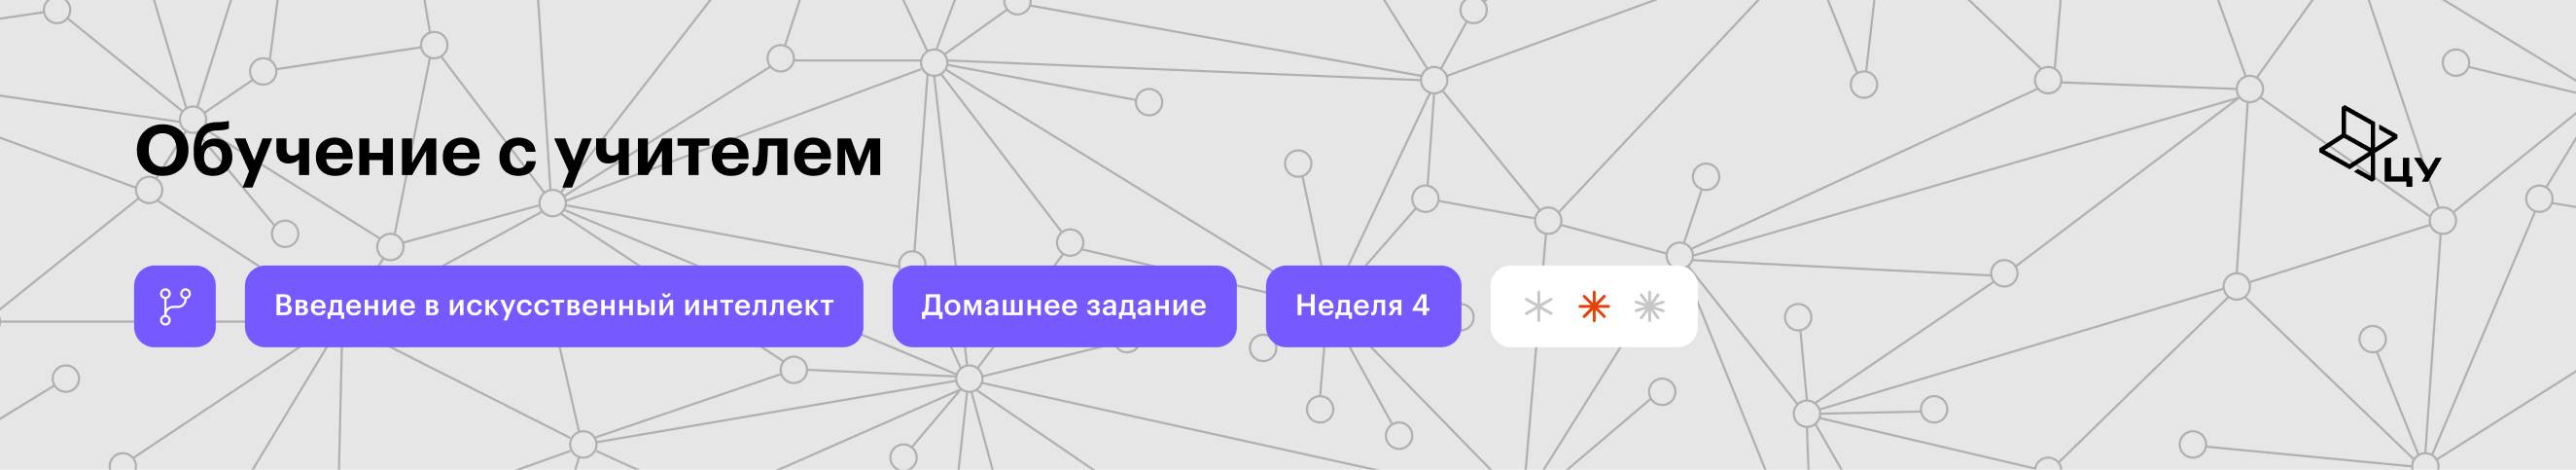

# Домашнее задание по теме «Линейные модели, KNN, нормализация и метрики»

В этом домашнем задании ты закрепишь основные идеи линейных моделей и метода ближайших соседей:
- найдёшь оптимальные коэффициенты линейной регрессии аналитически;
- проверишь аналитическое решение с помощью `sklearn`;
- выведешь формулу метода наименьших квадратов в общем случае;
- исследуешь вычислительную стоимость аналитического решения и проблему почти линейно зависимых признаков;
- разберёшься, почему коэффициенты линейной модели не всегда можно трактовать как важности признаков;
- проверишь, как нормализация влияет на логистическую регрессию и KNN;
- разберёшь, как изменение доли положительного класса влияет на `Precision` и `Recall`.

**Максимум за домашнее задание — 10 баллов.**

> ### Правила домашнего задания
>
> 1. Нельзя удалять существующие ячейки кода.
>
> 2. Можно добавлять и дописывать свои ячейки.
>
> 3. Место, куда тебе нужно написать код, помечается комментарием.
>
> 4. Ответ без кода, который подтверждает решение, не засчитывается. Исключение — задачи и вопросы, где код не требуется.
>
> 5. Код должен быть работоспособным. У проверяющих должна быть возможность воспроизвести все полученные результаты.
>
> 6. Все графики подписывай так, чтобы можно было легко понять их смысл.
>
> 7. Фиксируй `random_state` / `seed` для воспроизводимости результатов.
>
> 8. В заданиях с экспериментами недостаточно вывести числа — обязательно напиши краткий содержательный вывод.

## Установка библиотек

In [ ]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

SEED = 21
np.random.seed(SEED)

## Задание 1. Аналитическое решение линейной регрессии [1,5 балла]

Рассмотрим одномерную линейную регрессию


$$\hat y = wx + b$$

и функцию потерь MSE:


$$L(w,b)=\frac1n\sum_{i=1}^{n}(y_i-wx_i-b)^2.$$

Пусть дан датасет:

| \(x\) | 1 | 2 | 3 | 4 |
|---|---:|---:|---:|---:|
| \(y\) | 2 | 3 | 5 | 6 |


1. Выпиши необходимое условие максимума (равенство нулю градиента).

2. Получи формулы оптимальных коэффициентов w, b.

3. Вычисли их для данного датасета **вручную** или добавь ячейку с кодом расчёта.

4. Запиши итоговую формулу прямой $\hat y(x)$.

#### Ты можешь выбрать что-то одно.


1) Написать решение прямо тут, используя форматирование Latex:
$\frac{c}{\partial U} × \partial L  .$

2) Вставить (ctrl+v) фотографию в отдельную пустую текстовую ячейку в Google Collab.

3) Прикрепить подписанное фото своего решения вместе с ноутбуком.

## Задание 2. Проверка аналитического решения [1 балл]

Проверь результат из предыдущего задания с помощью `sklearn`.

1. Создай те же массивы `x` и `y`.
2. Обучи `LinearRegression`.
3. Выведи коэффициент и свободный член модели.
4. На одном графике нарисуй:
   - исходные точки;
   - прямую, полученную аналитически в задании 1;
   - прямую, полученную с помощью `sklearn`.
5. Сделай вывод, совпадают ли решения.

In [ ]:
# Данные из задания 1
x = np.array([1, 2, 3, 4], dtype=float)
y = np.array([2, 3, 5, 6], dtype=float)

# Напиши код здесь
...

#### Напиши вывод здесь.





## Задание 3. МНК в общем случае [3 балла]

Пусть теперь у нас есть $d$ признаков. Запишем линейную модель в матричном виде:

$
\hat{\mathbf y}=X\mathbf w,
$





*   где $X\in\mathbb{R}^{n\times d}$,
*   а      $\mathbf w\in\mathbb{R}^{d}.$



Свободный член — не проблема, просто добавим в наш датасет фиктивный признак с единицами.

Для данной задачи существует аналитическое решение:

$$
\boxed{
\mathbf w=(X^TX)^{-1}X^T\mathbf y.
}
$$






### Часть 1 [1 балл]

Напиши функцию `ols_closed_form(X, y)`, которая вычисляет коэффициенты именно по формуле выше.

Проверь её на случайном датасете и сравни коэффициенты с `LinearRegression`.

> **Примечание:** для простоты можешь самостоятельно добавить к \(X\) столбец единиц.

In [ ]:
# Часть 1. Реализуй аналитическое решение

def ols_closed_form(X, y):
    # Напиши код здесь
    ...

### Часть 2 [1 балл]

Исследуй время вычисления аналитического решения при разном числе объектов

$$
n\in\{1,10,100,1000,10000, 100000\}.
$$

1) В этом эксперименте используй **один признак** и свободный член.

2) Для маленьких `n` один замер очень шумный, поэтому лучше повторить вычисление много раз и взять медиану.


3) Построй график зависимости времени от `n`.

 **Примечание.**

Для измерения времени можно использовать следующее.


> Случай `n = 1` особенный; подумай, почему, и напиши. Возможно, его придётся обработать отдельно.

```python
start = time.perf_counter()
# Код, время которого измеряем
elapsed = time.perf_counter() - start
```


In [ ]:
# Часть 2. Эксперимент со временем

n_values = [1, 10, 100, 1000, 10000]

# Напиши код здесь
...

### Часть 3 [1 балл]

Исследуй, что происходит с линейной регрессией, если два признака почти линейно зависимы.

1. Сгенерируй первый признак $x_1$ и случайный шум noise. Второй признак построй по формуле:

$x_2 = x_1 + 10^{-6} × noise.$

2. Сохрани массив noise — он понадобится далее.

3. Сгенерируй целевую переменную y и найди коэффициенты линейной регрессии на признаках $x_1$ и $x_2$.

4. Выведи полученные коэффициенты модели. Обрати внимание на их величины и знаки.

5. Немного измени целевую переменную в направлении, по которому отличаются $x_1$ и $x_2$:
$y_{perturbed} = y + 10^{-4} × noise$,
и снова вычисли коэффициенты линейной регрессии.

6. Сравни:


*   коэффициенты до и после изменения y;
*   величину изменения самого y;

*   предсказания модели до и после изменения y.


7. Сделай выводы:
- о вычислительной стоимости аналитического решения;
- численной устойчивости при почти линейно зависимых признаках.

In [ ]:
# Часть 3. Почти линейно зависимые признаки

# Напиши код здесь
...

#### Напиши выводы здесь.

## Задание 4. Можно ли считать коэффициенты важностями признаков [1 балл]

Пусть в линейной модели есть два сильно зависимых признака:


$$x_2 \approx 2x_1.$$

Ответь без кода.

*  Почему в такой ситуации нельзя просто посмотреть на абсолютные значения коэффициентов $|w_1|,\ |w_2|$ и сказать, какой из двух признаков «важнее»?
*  Что произойдёт в случае **точной** линейной зависимости?
*  Что может происходить с коэффициентами при **почти** линейной зависимости?

#### Напиши ответ здесь.

## Задание 5. Как нормализация влияет на Logistic Regression и KNN [2,5 балла]

В этом задании будем использовать встроенный датасет `Breast Cancer Wisconsin`.

Ниже дан код загрузки данных.

In [ ]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Размер X:", X.shape)
print("Распределение классов:")
print(y.value_counts(normalize=True).sort_index())

X.head()

Размер X: (569, 30)
Распределение классов:
target
0    0.372583
1    0.627417
Name: proportion, dtype: float64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


1. Разбей данные на train и test в отношении 75/25. Используй `stratify=y`.

2. Обучи четыре модели:
   - `LogisticRegression` без нормализации;
   - `StandardScaler + LogisticRegression`;
   - `KNeighborsClassifier` без нормализации;
   - `StandardScaler + KNeighborsClassifier`.

3. Для всех моделей посчитай `Accuracy` на тесте.

4. Замерь время вызова `.fit()`.

5. Для логистической регрессии дополнительно выведи число итераций `n_iter_`.

6. Сведи результаты в одну таблицу.

7. Ответь на вопросы.
   - Почему нормализация может ускорить оптимизацию логистической регрессии?
   - Почему нормализация особенно важна для KNN?
   - Почему для KNN почти бессмысленно сравнивать именно время `.fit()` до и после нормализации?
   - Можно ли по одному эксперименту утверждать, что нормализация **всегда** повышает `Accuracy`?


> **Важно:** `StandardScaler` должен обучаться только на тренировочной выборке. Удобнее всего использовать `Pipeline`.

In [ ]:
# Напиши код здесь
...

#### Напиши выводы здесь

## Задание 6. Precision и Recall при изменении баланса классов [1 балл]

На тестовой выборке классы были распределены **1:1**.

В тесте было 1000 объектов:

- 500 объектов класса \(Y = 1\);
- 500 объектов класса \(Y = 0\).

Модель получила следующую матрицу ошибок:

$
TP=400,\qquad FN=100,\qquad FP=50,\qquad TN=450.
$


Позже выяснилось, что тестовая выборка была собрана неправильно.

На проде истинное распределение:


$P(Y=1)=0,05,\qquad P(Y=0)=0,95.$

Предположим, что свойства модели внутри каждого класса не изменились, то есть:

- `Recall`/TPR для положительного класса остаётся тем же;
- FPR для отрицательного класса остаётся тем же.





Чтобы оценить изменение качества модели на продакшене, нужно следующее.


1.   Найди `Recall` и `Precision` на исходном тесте.
2.   Восстанови ожидаемые \(TP,FN,FP,TN\) на основе 10 000 объектов на проде.
3. Пересчитай `Recall` на новых данных.
4. Пересчитай `Precision` на новых данных.
5. Объясни, почему одна из метрик осталась почти неизменной, а другая изменилась значительно.






#### Ты можешь выбрать что-то одно.


1) Написать решение прямо тут, используя форматирование Latex:
$\frac{c}{\partial U} × \partial L.$

2) Вставить (ctrl+v) фотографию в отдельную пустую текстовую ячейку в Google Collab.

3) Прикрепить подписанное фото своего решения вместе с ноутбуком.